# Model 5 — 2026 Race Finishing-Position Probabilities

**StintIQ | 2026-only, pre-race position model**

This notebook estimates the finishing-position distribution for each driver who starts in the top 10. For each selected driver it reports P1, P2, … through the size of the race field. P1 is also the driver's win probability.

The model uses the known starting grid and 2026 results from earlier rounds. It does **not** predict qualifying position or grid position.

## Scope and information boundary

- **Season:** 2026 only.
- **Forecast moment:** after the official starting grid is published and before the race.
- **Target:** final finishing position for each driver; the delivered table is limited to drivers starting P1–P10.
- **Output:** each selected driver's probabilities of finishing P1, P2, … Pn, where n is the number of race starters. Probabilities across positions sum to 100% for each driver.
- **Inputs:** qualifying position, official starting-grid position, and driver/team form from earlier 2026 rounds.
- **Validation:** rolling forward by race. A race's result is never used to train the prediction for that same race.
- **Baseline:** a starting-grid-only position model.

The season sample is small, so the probabilities are experimental. The model simulates complete race orders so each simulated result has one driver per finishing place. Only the top-10 starters are shown in the final forecast; drivers outside the top 10 still participate in those simulations.

## Setup

From the project root, install the project requirements in the same environment as this notebook:

```bash
python -m pip install -r requirements.txt
```

The requirements include FastF1 and Matplotlib. FastF1 supplies the 2026 event schedule, qualifying results, and official race classifications. The notebook enables its local cache so repeated runs do not need to download the same session data again.

In [19]:
from collections import defaultdict
from pathlib import Path
import warnings
import math

import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

In [20]:
# -----------------------------------------------------------------------------
# Configuration. Update PREDICTION_ROUND and HISTORICAL_ROUND_LIMIT as the season
# progresses. For a live forecast, history must stop at the last completed race.
# -----------------------------------------------------------------------------
SEASON = 2026
HISTORICAL_ROUND_LIMIT = 20
PREDICTION_ROUND = 21
BACKTEST_START_ROUND = 6
MIN_TRAINING_RACES = 5
POSITION_RIDGE_ALPHA = 10.0
POSITION_SIMULATIONS = 4000
RANDOM_STATE = 39

# Map driver abbreviations to official grid slots if grid penalties change the
# qualifying order and the target race's official grid is not available via FastF1.
GRID_OVERRIDES = {}

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CACHE_DIR = PROJECT_ROOT / "cache"
OUTPUT_DIR = PROJECT_ROOT / "model5_outputs"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fastf1.Cache.enable_cache(str(CACHE_DIR))

print(f"Season: {SEASON}")
print(f"Historical rounds requested: 1–{HISTORICAL_ROUND_LIMIT}")
print(f"Prediction round: {PREDICTION_ROUND}")
print(f"FastF1 cache: {CACHE_DIR}")

Season: 2026
Historical rounds requested: 1–20
Prediction round: 21
FastF1 cache: /Users/hemant/Work/StintIQ/cache


## 1. Load the 2026 calendar

Round numbers are used so the notebook can work even if event naming differs between data sources. Testing sessions are excluded.

In [21]:
season_schedule = fastf1.get_event_schedule(SEASON, include_testing=False).copy()
season_schedule["RoundNumber"] = pd.to_numeric(season_schedule["RoundNumber"], errors="coerce")
season_schedule = season_schedule.loc[season_schedule["RoundNumber"].fillna(0).gt(0)].copy()
season_schedule["RoundNumber"] = season_schedule["RoundNumber"].astype(int)
season_schedule = season_schedule.sort_values("RoundNumber").reset_index(drop=True)

if season_schedule.empty:
    raise RuntimeError(f"FastF1 returned no championship rounds for {SEASON}.")

schedule_columns = [
    col for col in ["RoundNumber", "Country", "Location", "EventName", "EventDate"]
    if col in season_schedule.columns
]
display(season_schedule[schedule_columns])

available_rounds = set(season_schedule["RoundNumber"].tolist())
if PREDICTION_ROUND not in available_rounds:
    raise ValueError(f"Round {PREDICTION_ROUND} is not in the {SEASON} schedule.")
if HISTORICAL_ROUND_LIMIT >= PREDICTION_ROUND:
    raise ValueError("HISTORICAL_ROUND_LIMIT must be less than PREDICTION_ROUND for a pre-race forecast.")

,RoundNumber,Country,Location,EventName,EventDate
0,1,Australia,Melbourne,Australian Grand Prix,2026-03-08
1,2,China,Shanghai,Chinese Grand Prix,2026-03-15
2,3,Japan,Suzuka,Japanese Grand Prix,2026-03-29
3,4,United States,Miami Gardens,Miami Grand Prix,2026-05-03
4,5,Canada,Montréal,Canadian Grand Prix,2026-05-24
5,6,Monaco,Monte Carlo,Monaco Grand Prix,2026-06-07
6,7,Spain,Barcelona,Barcelona Grand Prix,2026-06-14
7,8,Austria,Spielberg,Austrian Grand Prix,2026-06-28
8,9,United Kingdom,Silverstone,British Grand Prix,2026-07-05
9,10,Belgium,Spa-Francorchamps,Belgian Grand Prix,2026-07-19


## 2. Download qualifying and race classifications

Only lightweight session results are requested; lap telemetry is not needed for this position model. Historical rounds need qualifying, official starting-grid, and race-classification results. The target round needs qualifying, and the published grid if available; its finishing result is never used for the forecast.

In [22]:
def load_session_results(round_number: int, session_code: str) -> pd.DataFrame:
    """Load a FastF1 session result table without loading laps or telemetry."""
    session = fastf1.get_session(SEASON, int(round_number), session_code)
    session.load(laps=False, telemetry=False, weather=False, messages=False)
    results = session.results.copy()
    if results.empty:
        raise RuntimeError(f"No {session_code} results available for round {round_number}.")
    return results


def normalize_qualifying_results(raw: pd.DataFrame, round_number: int) -> pd.DataFrame:
    required = {"Abbreviation", "TeamName", "Position"}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"Qualifying results for round {round_number} lack columns: {sorted(missing)}")

    q = raw.loc[:, ["Abbreviation", "TeamName", "Position"]].copy()
    q = q.dropna(subset=["Abbreviation"])
    q["Driver"] = q["Abbreviation"].astype(str).str.strip()
    q["Team"] = q["TeamName"].fillna("Unknown").astype(str).str.strip()
    q["QualifyingPosition"] = pd.to_numeric(q["Position"], errors="coerce")
    q = q.drop_duplicates(subset="Driver", keep="first")

    if q["QualifyingPosition"].notna().sum() == 0:
        raise RuntimeError(f"No usable qualifying positions for round {round_number}.")

    # Drivers without a recorded time remain in the field behind the classified qualifiers.
    missing_position = q["QualifyingPosition"].isna()
    next_position = int(q["QualifyingPosition"].max()) + 1
    q.loc[missing_position, "QualifyingPosition"] = np.arange(
        next_position, next_position + int(missing_position.sum())
    )
    q["QualifyingPosition"] = q["QualifyingPosition"].astype(float)
    q["StartingGridPosition"] = q["QualifyingPosition"]
    return q[["Driver", "Team", "QualifyingPosition", "StartingGridPosition"]].sort_values("QualifyingPosition").reset_index(drop=True)


def normalize_race_results(raw: pd.DataFrame, round_number: int) -> pd.DataFrame:
    required = {"Abbreviation", "TeamName", "Position"}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"Race results for round {round_number} lack columns: {sorted(missing)}")

    columns = ["Abbreviation", "TeamName", "Position"]
    if "GridPosition" in raw.columns:
        columns.append("GridPosition")
    race = raw.loc[:, columns].copy()
    race = race.dropna(subset=["Abbreviation"])
    race["Driver"] = race["Abbreviation"].astype(str).str.strip()
    race["Team"] = race["TeamName"].fillna("Unknown").astype(str).str.strip()
    race["FinishPosition"] = pd.to_numeric(race["Position"], errors="coerce")
    if "GridPosition" in race.columns:
        race["StartingGridPosition"] = pd.to_numeric(race["GridPosition"], errors="coerce")
    else:
        race["StartingGridPosition"] = np.nan
    race = race.drop_duplicates(subset="Driver", keep="first")

    # Keep unclassified entries in the race-order target by assigning missing
    # numeric places after classified positions. FastF1's result table is sorted
    # by classification, so this preserves the tail order for DNFs.
    used = set(race["FinishPosition"].dropna().astype(int).tolist())
    available = [place for place in range(1, len(race) + 1) if place not in used]
    next_place = max(used, default=0) + 1
    for index in race.index[race["FinishPosition"].isna()]:
        place = available.pop(0) if available else next_place
        race.loc[index, "FinishPosition"] = place
        next_place = max(next_place, place + 1)
    race["FinishPosition"] = race["FinishPosition"].astype(int)

    winner_count = int(race["FinishPosition"].eq(1).sum())
    if winner_count != 1:
        raise RuntimeError(f"Expected one classified winner for round {round_number}; found {winner_count}.")
    return race[["Driver", "Team", "FinishPosition", "StartingGridPosition"]]


def load_round(round_number: int, include_race_result: bool = True) -> dict:
    q_raw = load_session_results(round_number, "Q")
    q = normalize_qualifying_results(q_raw, round_number)
    race = None
    if include_race_result:
        r_raw = load_session_results(round_number, "R")
        race = normalize_race_results(r_raw, round_number)
    return {"round": int(round_number), "qualifying": q, "race": race}

### Load historical rounds

This cell uses the existing local FastF1 cache where possible and downloads missing session results. If the source has not published a requested session yet, the error names the round and session so the range can be adjusted.

In [23]:
historical_rounds = [
    int(r) for r in season_schedule["RoundNumber"]
    if 1 <= int(r) <= HISTORICAL_ROUND_LIMIT
]

event_data = {}
for round_number in historical_rounds:
    event_name = season_schedule.loc[
        season_schedule["RoundNumber"].eq(round_number), "EventName"
    ].iloc[0]
    print(f"Loading R{round_number:02d}: {event_name}")
    event_data[round_number] = load_round(round_number, include_race_result=True)

print(f"Loaded {len(event_data)} completed-round bundles.")

core           INFO 	Loading data for Australian Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...


Loading R01: Australian Grand Prix


logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 19 drivers: ['63', '12', '6', '16', '81', '1', '44', '30', '41', '5', '27', '87', '31', '10', '23', '43', '14', '11', '77']
core           INFO 	Loading data for Australian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
core           INFO 	Finished loading data for 22 drivers: ['63', '12', '16', '44', '1', '3', '87', '41', '5', '10', '31', '23', '30', '43', '55', '11', '18', '14', '77', '6', '81', '27']
core           INFO 	Loading data for Chinese Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...


Loading R02: Chinese Grand Prix


logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['12', '63', '44', '16', '81', '1', '10', '3', '6', '87', '27', '43', '31', '30', '41', '5', '55', '23', '14', '77', '18', '11']
core           INFO 	Loading data for Chinese Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['12', '63', '44', '16', '87', '10', '30', '6', '55', '43', '27', '41', '

Loading R03: Japanese Grand Prix


... (32 outputs left out)

logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['44', '63', '16', '3', '12', '1', '6', '41', '10', '27', '43', '81', '5', '87', '55', '23', '14', '50', '18', '11', '77', '30']
core           INFO 	Loading data for Mexico City Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['3', '44', '12', '16', '1', '63', '30', '5', '6', '50', '23', '55', 

Loading R20: São Paulo Grand Prix


logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['1', '63', '12', '16', '30', '27', '6', '87', '14', '23', '44', '81', '51', '41', '55', '3', '43', '10', '18', '77', '11', '5']
core           INFO 	Loading data for São Paulo Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core           INFO 	Finished loading data for 22 drivers: ['1', '3', '6', '63', '12', '81', '30', '16', '44', '27', '41', '14', '

Loaded 20 completed-round bundles.


## 3. Build leakage-safe pre-race features

For each round, features are created before that round's result is added to the driver's or team's history. This is the key time boundary for both model fitting and walk-forward validation.

In [24]:
FEATURE_COLUMNS = [
    "starting_grid_position",
    "qualifying_position",
    "driver_prev3_avg_finish",
    "driver_prev5_win_rate",
    "driver_prev5_top3_rate",
    "driver_prior_starts",
    "team_prev3_avg_finish",
    "team_prev5_win_rate",
    "team_prev5_top3_rate",
]


def recent_average(records: list, key: str, n: int, default: float) -> float:
    values = [float(row[key]) for row in records[-n:] if row.get(key) is not None and np.isfinite(row[key])]
    return float(np.mean(values)) if values else float(default)


def recent_rate(records: list, key: str, n: int) -> float:
    values = [float(row[key]) for row in records[-n:] if row.get(key) is not None]
    return float(np.mean(values)) if values else 0.0


def make_pre_race_features(
    qualifying: pd.DataFrame,
    driver_history: dict,
    team_history: dict,
    round_number: int,
    event_name: str,
) -> pd.DataFrame:
    field_size = max(len(qualifying), 1)
    neutral_finish = (field_size + 1.0) / 2.0
    rows = []

    for row in qualifying.itertuples(index=False):
        driver_records = driver_history.get(row.Driver, [])
        team_records = team_history.get(row.Team, [])
        rows.append({
            "Season": SEASON,
            "RoundNumber": int(round_number),
            "EventName": event_name,
            "Driver": row.Driver,
            "Team": row.Team,
            "qualifying_position": float(row.QualifyingPosition),
            "starting_grid_position": float(getattr(row, "StartingGridPosition", row.QualifyingPosition)),
            "driver_prev3_avg_finish": recent_average(driver_records, "finish", 3, neutral_finish),
            "driver_prev5_win_rate": recent_rate(driver_records, "win", 5),
            "driver_prev5_top3_rate": recent_rate(driver_records, "top3", 5),
            "driver_prior_starts": float(len(driver_records)),
            "team_prev3_avg_finish": recent_average(team_records, "avg_finish", 3, neutral_finish),
            "team_prev5_win_rate": recent_rate(team_records, "win", 5),
            "team_prev5_top3_rate": recent_rate(team_records, "top3", 5),
        })

    frame = pd.DataFrame(rows)
    if frame.empty:
        raise RuntimeError(f"No qualifying drivers available for round {round_number}.")
    return frame


def add_completed_race_to_history(
    race_results: pd.DataFrame,
    driver_history: dict,
    team_history: dict,
) -> None:
    field_size = max(len(race_results), 1)
    race = race_results.copy()
    # Unclassified finishers are assigned behind the classified field in prior-form features.
    race["FinishPosition"] = race["FinishPosition"].fillna(float(field_size + 1))
    race["Win"] = race["FinishPosition"].eq(1).astype(float)
    race["Top3"] = race["FinishPosition"].le(3).astype(float)

    for row in race.itertuples(index=False):
        driver_history[row.Driver].append({
            "finish": float(row.FinishPosition),
            "win": float(row.Win),
            "top3": float(row.Top3),
        })

    for team, group in race.groupby("Team", dropna=False):
        team_history[str(team)].append({
            "avg_finish": float(group["FinishPosition"].mean()),
            "win": float(group["Win"].max()),
            "top3": float(group["Top3"].max()),
        })


def build_leakage_safe_tables(event_data: dict, schedule: pd.DataFrame):
    driver_history = defaultdict(list)
    team_history = defaultdict(list)
    feature_frames = {}
    outcome_frames = {}

    for round_number in sorted(event_data):
        event_name = schedule.loc[
            schedule["RoundNumber"].eq(round_number), "EventName"
        ].iloc[0]
        bundle = event_data[round_number]

        race = bundle.get("race")
        qualifying_entries = bundle["qualifying"].copy()
        if race is not None:
            grid_lookup = race[["Driver", "StartingGridPosition"]].drop_duplicates("Driver")
            qualifying_entries = qualifying_entries.merge(grid_lookup, on="Driver", how="left", suffixes=("", "_Official"))
            official_grid = qualifying_entries["StartingGridPosition_Official"]
            qualifying_entries["StartingGridPosition"] = official_grid.fillna(qualifying_entries["QualifyingPosition"])
            qualifying_entries = qualifying_entries.drop(columns=["StartingGridPosition_Official"])

        # Snapshot features first: the current round's result is not in history yet.
        features = make_pre_race_features(
            qualifying_entries, driver_history, team_history, round_number, event_name
        )
        feature_frames[round_number] = features

        if race is not None:
            race_targets = race[["Driver", "FinishPosition"]].drop_duplicates("Driver")
            features_with_target = features.merge(race_targets, on="Driver", how="inner")
            features_with_target["Winner"] = features_with_target["FinishPosition"].eq(1).astype(int)
            if int(features_with_target["Winner"].sum()) == 1:
                outcome_frames[round_number] = features_with_target
            else:
                warnings.warn(
                    f"Round {round_number} does not have exactly one winner among classified entries; "
                    "it will be excluded from training and scoring."
                )
            # Only after feature creation do this round's official results update history.
            add_completed_race_to_history(race, driver_history, team_history)

    return feature_frames, outcome_frames, driver_history, team_history


feature_frames, outcome_frames, driver_history, team_history = build_leakage_safe_tables(
    event_data, season_schedule
)

labelled_data = pd.concat(outcome_frames.values(), ignore_index=True)
print(f"Feature rows: {sum(len(frame) for frame in feature_frames.values()):,}")
print(f"Completed labeled rounds: {len(outcome_frames)}")
print(f"Labeled driver-race rows: {len(labelled_data):,}")
display(labelled_data.head(10))

Feature rows: 435
Completed labeled rounds: 20
Labeled driver-race rows: 435


,Season,RoundNumber,EventName,Driver,Team,qualifying_position,starting_grid_position,driver_prev3_avg_finish,driver_prev5_win_rate,driver_prev5_top3_rate,driver_prior_starts,team_prev3_avg_finish,team_prev5_win_rate,team_prev5_top3_rate,FinishPosition,Winner
0,2026,1,Australian Grand Prix,RUS,Mercedes,1.0,1.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,1,1
1,2026,1,Australian Grand Prix,ANT,Mercedes,2.0,2.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,2,0
2,2026,1,Australian Grand Prix,HAD,Red Bull,3.0,3.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,20,0
3,2026,1,Australian Grand Prix,LEC,Ferrari,4.0,4.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,3,0
4,2026,1,Australian Grand Prix,PIA,McLaren,5.0,5.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,21,0
5,2026,1,Australian Grand Prix,NOR,McLaren,6.0,6.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,5,0
6,2026,1,Australian Grand Prix,HAM,Ferrari,7.0,7.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,4,0
7,2026,1,Australian Grand Prix,LAW,RB F1 Team,8.0,8.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,13,0
8,2026,1,Australian Grand Prix,LIN,RB F1 Team,9.0,9.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,8,0
9,2026,1,Australian Grand Prix,BOR,Audi,10.0,10.0,10.0,0.0,0.0,0.0,10.0,0.0,0.0,9,0


## 4. Inspect the 2026 data

These charts describe the loaded season data. They are exploratory summaries, not out-of-sample model scores.

,RoundNumber,EventName,Winner,Team,QualifyingPosition
0,1,Australian Grand Prix,RUS,Mercedes,1.0
1,2,Chinese Grand Prix,ANT,Mercedes,1.0
2,3,Japanese Grand Prix,ANT,Mercedes,1.0
3,4,Miami Grand Prix,ANT,Mercedes,1.0
4,5,Canadian Grand Prix,ANT,Mercedes,2.0
5,6,Monaco Grand Prix,ANT,Mercedes,1.0
6,7,Barcelona Grand Prix,HAM,Ferrari,2.0
7,8,Austrian Grand Prix,RUS,Mercedes,1.0
8,9,British Grand Prix,LEC,Ferrari,2.0
9,10,Belgian Grand Prix,ANT,Mercedes,1.0


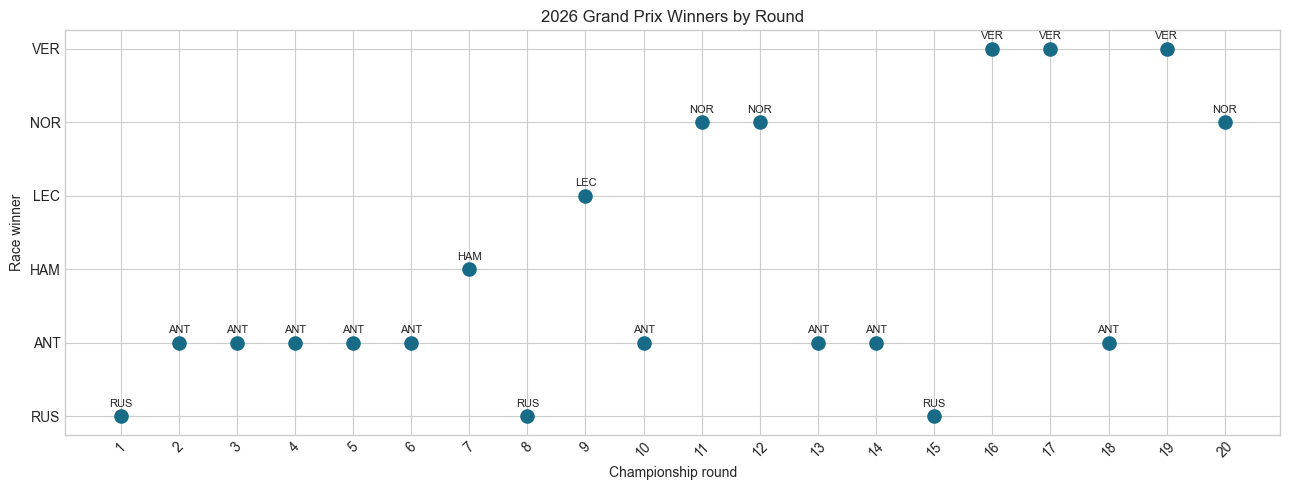

In [25]:
# Winner by round and driver.
winner_records = []
for round_number, frame in outcome_frames.items():
    winner_row = frame.loc[frame["Winner"].eq(1)].iloc[0]
    winner_records.append({
        "RoundNumber": round_number,
        "EventName": winner_row["EventName"],
        "Winner": winner_row["Driver"],
        "Team": winner_row["Team"],
        "QualifyingPosition": winner_row["qualifying_position"],
    })
winners_df = pd.DataFrame(winner_records).sort_values("RoundNumber")
display(winners_df)

fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(winners_df["RoundNumber"], winners_df["Winner"], s=90, color="#176B87")
for row in winners_df.itertuples(index=False):
    ax.annotate(row.Winner, (row.RoundNumber, row.Winner), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.set_title("2026 Grand Prix Winners by Round")
ax.set_xlabel("Championship round")
ax.set_ylabel("Race winner")
ax.set_xticks(winners_df["RoundNumber"])
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

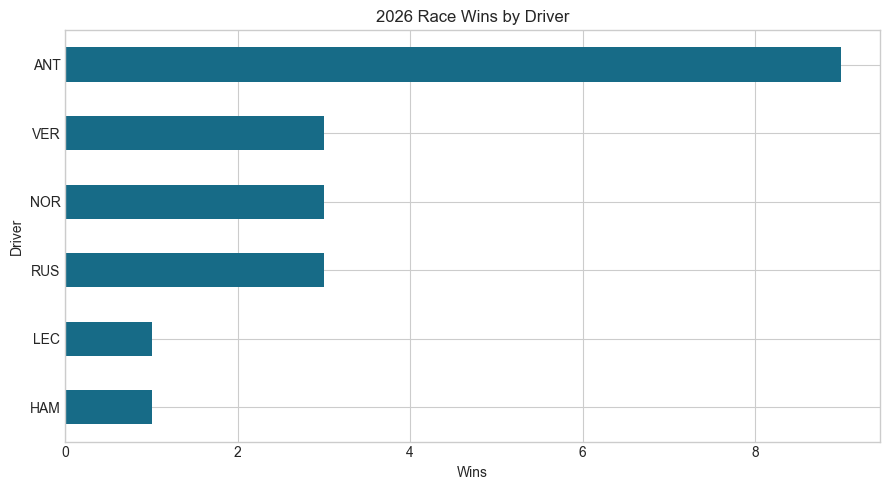

In [26]:
# Season win counts by driver.
win_counts = winners_df["Winner"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
win_counts.plot(kind="barh", ax=ax, color="#176B87")
ax.set_title("2026 Race Wins by Driver")
ax.set_xlabel("Wins")
ax.set_ylabel("Driver")
plt.tight_layout()
plt.show()

,qualifying_position,Starts,Wins,ObservedWinRate
0,1.0,20,14,0.70
1,2.0,20,4,0.20
2,3.0,20,0,0.00
3,4.0,20,1,0.05
4,5.0,20,0,0.00
5,6.0,20,0,0.00
6,7.0,20,1,0.05
7,8.0,20,0,0.00
8,9.0,20,0,0.00
9,10.0,20,0,0.00


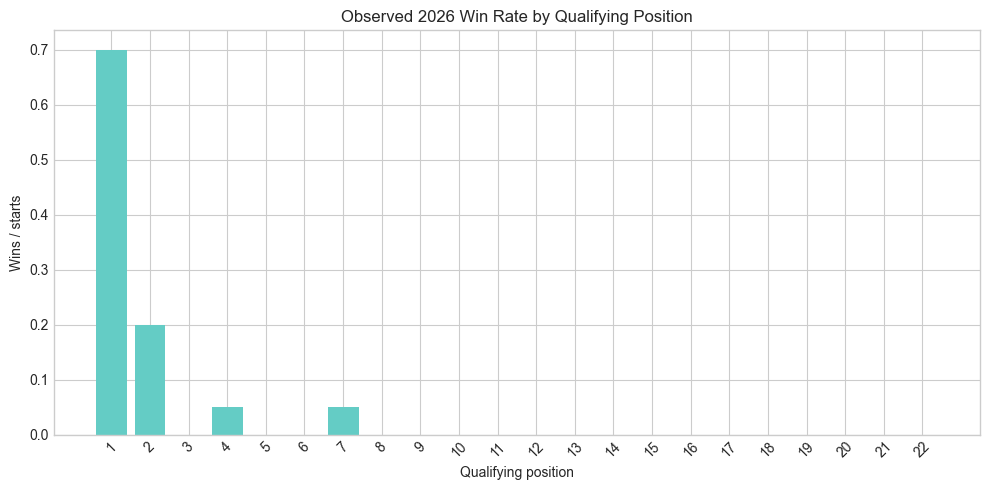

In [27]:
# Descriptive win rate by qualifying position.
qualifying_summary = (
    labelled_data.groupby("qualifying_position", as_index=False)
    .agg(Starts=("Winner", "size"), Wins=("Winner", "sum"))
)
qualifying_summary["ObservedWinRate"] = qualifying_summary["Wins"] / qualifying_summary["Starts"]
display(qualifying_summary.head(15))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(qualifying_summary["qualifying_position"], qualifying_summary["ObservedWinRate"], color="#64CCC5")
ax.set_title("Observed 2026 Win Rate by Qualifying Position")
ax.set_xlabel("Qualifying position")
ax.set_ylabel("Wins / starts")
ax.set_xticks(qualifying_summary["qualifying_position"])
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5. Model 5: finishing-position probabilities for top-10 starters

The model fits a regularized position regressor from all classified race entries. At prediction time it uses the official starting grid and simulates full-field race orders by adding empirical 2026 position-change variation, then sorting the field into unique places. This yields a probability distribution P1…Pn for each driver.

The final forecast displays only drivers with starting-grid position 1–10. Historical training uses official Race-session `GridPosition`; for the target race the notebook tries to obtain the published grid and otherwise uses qualifying order as a clearly marked proxy. Use `GRID_OVERRIDES` for any official penalty-adjusted grid positions that are not available through FastF1.

In [28]:
from sklearn.linear_model import Ridge

POSITION_FEATURES = FEATURE_COLUMNS.copy()
GRID_ONLY_POSITION_FEATURES = ["starting_grid_position"]
POSITION_COUNT = max(
    max(len(frame) for frame in outcome_frames.values()),
    max((int(frame["FinishPosition"].max()) for frame in outcome_frames.values()), default=1),
)

# Attach official start positions to the already leakage-safe pre-race feature rows.
position_feature_frames = {}
position_outcome_frames = {}
for round_number, base_features in feature_frames.items():
    bundle_race = event_data[round_number].get("race")
    if bundle_race is None:
        continue
    official_grid = bundle_race[["Driver", "StartingGridPosition"]].drop_duplicates("Driver")
    position_features = base_features.drop(columns=["starting_grid_position"], errors="ignore").merge(
        official_grid, on="Driver", how="left"
    )
    position_features["starting_grid_position"] = position_features["StartingGridPosition"].fillna(
        position_features["qualifying_position"]
    )
    position_features = position_features.drop(columns=["StartingGridPosition"])
    position_feature_frames[round_number] = position_features

    targets = bundle_race[["Driver", "FinishPosition"]].drop_duplicates("Driver")
    position_outcomes = position_features.merge(targets, on="Driver", how="inner")
    if not position_outcomes.empty:
        position_outcome_frames[round_number] = position_outcomes

if not position_outcome_frames:
    raise RuntimeError("No completed race rows are available for the finishing-position model.")

max_field_size = max(len(frame) for frame in position_outcome_frames.values())
POSITION_COUNT = max(max_field_size, POSITION_COUNT)
print(f"Position-model training rounds: {len(position_outcome_frames)}")
print(f"Race-position columns: P1 through P{POSITION_COUNT}")
print(f"Training entries: {sum(len(frame) for frame in position_outcome_frames.values()):,}")

Position-model training rounds: 20
Race-position columns: P1 through P22
Training entries: 435


In [29]:
def build_position_regressor(feature_columns: list):
    return make_pipeline(
        StandardScaler(),
        Ridge(alpha=POSITION_RIDGE_ALPHA),
    )

def grid_band(position: float) -> str:
    if position <= 5:
        return "front"
    if position <= 10:
        return "top10"
    return "outside_top10"

def position_change_noise(training_rows: pd.DataFrame) -> dict:
    """Return centered historical finish-minus-grid movement pools by grid band."""
    work = training_rows[["starting_grid_position", "FinishPosition"]].dropna().copy()
    work["GridBand"] = work["starting_grid_position"].map(grid_band)
    work["PositionChange"] = work["FinishPosition"] - work["starting_grid_position"]
    band_means = work.groupby("GridBand")["PositionChange"].mean().to_dict()
    work["CenteredMovement"] = work["PositionChange"] - work["GridBand"].map(band_means)
    global_pool = work["CenteredMovement"].to_numpy(dtype=float)
    if len(global_pool) < 5:
        global_pool = np.array([-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
    pools = {"global": global_pool}
    for band, group in work.groupby("GridBand"):
        values = group["CenteredMovement"].to_numpy(dtype=float)
        pools[band] = values if len(values) >= 8 else global_pool
    return pools

def simulate_position_probabilities(
    expected_positions: np.ndarray,
    starting_grid_positions: np.ndarray,
    noise_pools: dict,
    position_count: int,
    simulations: int = POSITION_SIMULATIONS,
    random_seed: int = RANDOM_STATE,
) -> np.ndarray:
    """Simulate complete rankings and return P(driver finishes each place)."""
    expected_positions = np.asarray(expected_positions, dtype=float).reshape(-1)
    starting_grid_positions = np.asarray(starting_grid_positions, dtype=float).reshape(-1)
    n_drivers = len(expected_positions)
    if n_drivers == 0:
        return np.zeros((0, position_count), dtype=float)

    rng = np.random.default_rng(random_seed)
    noise = np.empty((simulations, n_drivers), dtype=float)
    for driver_index, grid_position in enumerate(starting_grid_positions):
        pool = noise_pools.get(grid_band(grid_position), noise_pools["global"])
        noise[:, driver_index] = rng.choice(pool, size=simulations, replace=True)

    simulated_scores = expected_positions[None, :] + noise
    orders = np.argsort(simulated_scores, axis=1)
    ranks = np.argsort(orders, axis=1) + 1
    probabilities = np.zeros((n_drivers, position_count), dtype=float)
    for driver_index in range(n_drivers):
        counts = np.bincount(ranks[:, driver_index], minlength=position_count + 1)[1:position_count + 1]
        probabilities[driver_index] = counts / simulations
    return probabilities

def distribution_summary(frame: pd.DataFrame, probabilities: np.ndarray, position_count: int) -> pd.DataFrame:
    result = frame.copy().reset_index(drop=True)
    places = np.arange(1, position_count + 1)
    result["ExpectedFinishPosition"] = probabilities @ places
    result["MostLikelyFinishPosition"] = probabilities.argmax(axis=1) + 1
    result["WinProbabilityPct"] = probabilities[:, 0] * 100
    result["PodiumProbabilityPct"] = probabilities[:, :min(3, position_count)].sum(axis=1) * 100
    result["ProbabilityMassPct"] = probabilities.sum(axis=1) * 100
    for place in places:
        result[f"P{place}"] = probabilities[:, place - 1] * 100
    return result

def distribution_metrics(frame: pd.DataFrame, probabilities: np.ndarray) -> dict:
    actual = frame["FinishPosition"].to_numpy(dtype=int)
    places = np.arange(1, probabilities.shape[1] + 1)
    expected = probabilities @ places
    chosen_probability = probabilities[np.arange(len(actual)), actual - 1]
    cdf = np.cumsum(probabilities, axis=1)[:, :-1]
    actual_cdf = (actual[:, None] <= places[:-1][None, :]).astype(float)
    ranked_probability_score = np.mean(np.sum((cdf - actual_cdf) ** 2, axis=1) / max(len(places) - 1, 1))
    return {
        "PositionMAE": float(np.mean(np.abs(expected - actual))),
        "ActualPositionLogLoss": float(-np.mean(np.log(np.clip(chosen_probability, 1e-12, 1.0)))),
        "RankedProbabilityScore": float(ranked_probability_score),
    }

def run_position_walk_forward(position_outcomes: dict):
    metric_rows = []
    prediction_rows = []
    completed_rounds = sorted(position_outcomes)

    for target_round in completed_rounds:
        if target_round < BACKTEST_START_ROUND:
            continue
        prior_rounds = [round_number for round_number in completed_rounds if round_number < target_round]
        if len(prior_rounds) < MIN_TRAINING_RACES:
            continue

        train = pd.concat([position_outcomes[r] for r in prior_rounds], ignore_index=True)
        test = position_outcomes[target_round].copy().reset_index(drop=True)
        actual_top10 = test["starting_grid_position"].between(1, 10).to_numpy()
        if int(actual_top10.sum()) == 0:
            continue

        model = build_position_regressor(POSITION_FEATURES)
        model.fit(train[POSITION_FEATURES], train["FinishPosition"])
        raw_expected = np.clip(model.predict(test[POSITION_FEATURES]), 1, len(test))

        grid_model = build_position_regressor(GRID_ONLY_POSITION_FEATURES)
        grid_model.fit(train[GRID_ONLY_POSITION_FEATURES], train["FinishPosition"])
        grid_expected = np.clip(grid_model.predict(test[GRID_ONLY_POSITION_FEATURES]), 1, len(test))

        noise_pools = position_change_noise(train)
        model_probs = simulate_position_probabilities(
            raw_expected, test["starting_grid_position"].to_numpy(), noise_pools, POSITION_COUNT,
            random_seed=RANDOM_STATE + target_round,
        )
        grid_probs = simulate_position_probabilities(
            grid_expected, test["starting_grid_position"].to_numpy(), noise_pools, POSITION_COUNT,
            random_seed=RANDOM_STATE + target_round,
        )
        top10 = test.loc[actual_top10].reset_index(drop=True)
        model_top10_probs = model_probs[actual_top10]
        grid_top10_probs = grid_probs[actual_top10]
        model_metrics = distribution_metrics(top10, model_top10_probs)
        grid_metrics = distribution_metrics(top10, grid_top10_probs)

        metric_rows.append({
            "RoundNumber": target_round,
            "EventName": test["EventName"].iloc[0],
            "TrainingRaces": len(prior_rounds),
            "Top10Starters": int(actual_top10.sum()),
            "ModelPositionMAE": model_metrics["PositionMAE"],
            "GridPositionMAE": grid_metrics["PositionMAE"],
            "ModelPositionLogLoss": model_metrics["ActualPositionLogLoss"],
            "GridPositionLogLoss": grid_metrics["ActualPositionLogLoss"],
            "ModelRPS": model_metrics["RankedProbabilityScore"],
            "GridRPS": grid_metrics["RankedProbabilityScore"],
        })

        summary = distribution_summary(top10, model_top10_probs, POSITION_COUNT)
        grid_summary = distribution_summary(top10, grid_top10_probs, POSITION_COUNT)
        probability_columns = [f"P{place}" for place in range(1, POSITION_COUNT + 1)]
        for row_index, row in summary.iterrows():
            prediction = {
                "RoundNumber": target_round,
                "EventName": row["EventName"],
                "Driver": row["Driver"],
                "StartingGridPosition": row["starting_grid_position"],
                "ActualFinishPosition": row["FinishPosition"],
                "ExpectedFinishPosition": row["ExpectedFinishPosition"],
                "WinProbabilityPct": row["WinProbabilityPct"],
                "PodiumProbabilityPct": row["PodiumProbabilityPct"],
            }
            for column in probability_columns:
                prediction[column] = row[column]
                prediction[f"GridOnly_{column}"] = grid_summary.loc[row_index, column]
            prediction_rows.append(prediction)

    return pd.DataFrame(metric_rows), pd.DataFrame(prediction_rows)

position_backtest_metrics, position_backtest_predictions = run_position_walk_forward(position_outcome_frames)
display(position_backtest_metrics)

,RoundNumber,EventName,TrainingRaces,Top10Starters,ModelPositionMAE,GridPositionMAE,ModelPositionLogLoss,GridPositionLogLoss,ModelRPS,GridRPS
0,6,Monaco Grand Prix,5,10,6.545675,6.620625,2.586491,2.760977,0.195303,0.195407
1,7,Barcelona Grand Prix,6,10,5.454700,4.944275,2.436994,2.478815,0.148651,0.133524
2,8,Austrian Grand Prix,7,10,2.988425,2.934800,2.586241,2.529518,0.087532,0.084564
3,9,British Grand Prix,8,10,5.225300,5.001375,2.461019,2.440573,0.148525,0.139035
4,10,Belgian Grand Prix,9,10,3.799200,3.852800,2.391294,2.431933,0.120898,0.122887
5,11,Hungarian Grand Prix,10,10,3.451400,3.895700,2.408138,2.343304,0.107734,0.115011
6,12,Dutch Grand Prix,11,10,3.790400,3.882325,2.608279,2.404660,0.118126,0.114670
7,13,Italian Grand Prix,12,10,3.476550,3.770150,2.682193,2.660432,0.129577,0.133097
8,14,Spanish Grand Prix,13,10,3.633100,3.850850,4.365773,4.530828,0.102352,0.109962
9,15,Azerbaijan Grand Prix,14,10,5.550875,5.492800,3.083929,3.300801,0.174416,0.181583


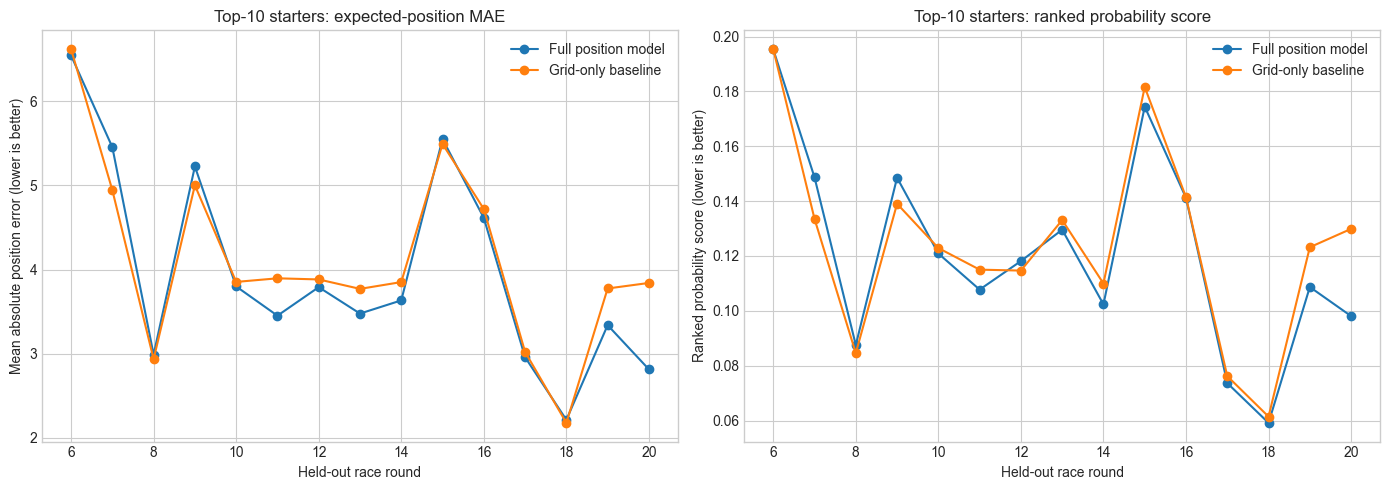

,RoundNumber,EventName,Driver,StartingGridPosition,ActualFinishPosition,ExpectedFinishPosition,WinProbabilityPct,PodiumProbabilityPct
120,18,United States Grand Prix,ANT,1.0,1,4.72700,31.725,68.625
121,18,United States Grand Prix,VER,2.0,3,4.44050,44.800,70.950
122,18,United States Grand Prix,HAD,3.0,6,5.85625,8.900,54.925
123,18,United States Grand Prix,LEC,4.0,2,6.30150,4.675,40.700
124,18,United States Grand Prix,HAM,5.0,4,6.77250,2.050,28.900
125,18,United States Grand Prix,RUS,6.0,8,7.45250,1.575,13.650
126,18,United States Grand Prix,PIA,7.0,7,8.90100,0.300,3.850
127,18,United States Grand Prix,NOR,8.0,5,9.06250,0.050,3.625
128,18,United States Grand Prix,LAW,9.0,9,10.41375,0.000,0.750
129,18,United States Grand Prix,GAS,10.0,10,11.82075,0.000,0.150


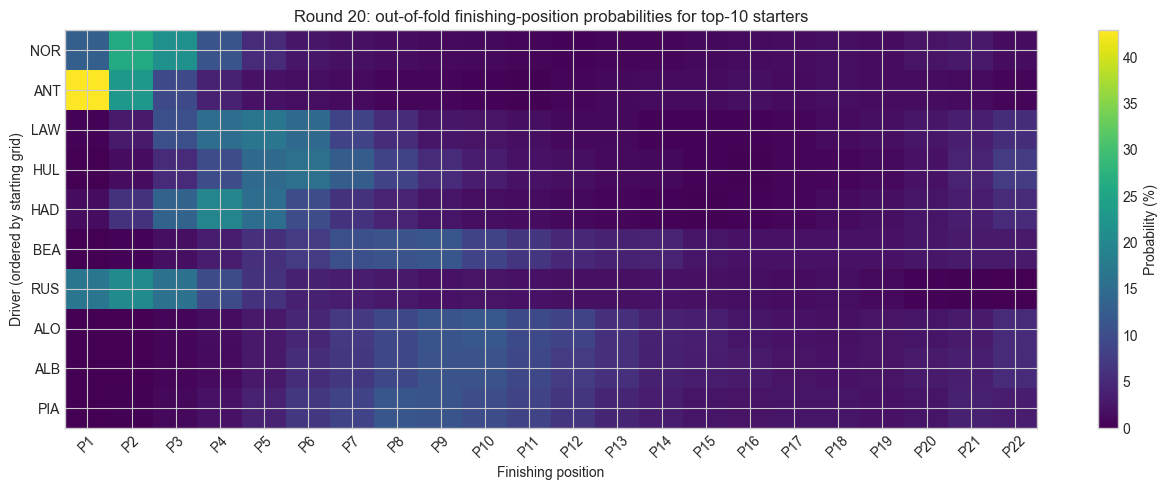

In [30]:
if not position_backtest_metrics.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(position_backtest_metrics["RoundNumber"], position_backtest_metrics["ModelPositionMAE"], marker="o", label="Full position model")
    axes[0].plot(position_backtest_metrics["RoundNumber"], position_backtest_metrics["GridPositionMAE"], marker="o", label="Grid-only baseline")
    axes[0].set_title("Top-10 starters: expected-position MAE")
    axes[0].set_xlabel("Held-out race round")
    axes[0].set_ylabel("Mean absolute position error (lower is better)")
    axes[0].legend()

    axes[1].plot(position_backtest_metrics["RoundNumber"], position_backtest_metrics["ModelRPS"], marker="o", label="Full position model")
    axes[1].plot(position_backtest_metrics["RoundNumber"], position_backtest_metrics["GridRPS"], marker="o", label="Grid-only baseline")
    axes[1].set_title("Top-10 starters: ranked probability score")
    axes[1].set_xlabel("Held-out race round")
    axes[1].set_ylabel("Ranked probability score (lower is better)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

late_position_test = position_backtest_predictions.loc[
    position_backtest_predictions["RoundNumber"].between(18, 20)
].copy()
display(late_position_test[[
    "RoundNumber", "EventName", "Driver", "StartingGridPosition", "ActualFinishPosition",
    "ExpectedFinishPosition", "WinProbabilityPct", "PodiumProbabilityPct"
]])

if not late_position_test.empty:
    selected_round = int(late_position_test["RoundNumber"].max())
    heat = late_position_test.loc[late_position_test["RoundNumber"].eq(selected_round)].sort_values("StartingGridPosition")
    probability_columns = [f"P{place}" for place in range(1, POSITION_COUNT + 1)]
    matrix = heat[probability_columns].to_numpy()
    fig, ax = plt.subplots(figsize=(13, 5))
    im = ax.imshow(matrix, aspect="auto", interpolation="nearest", cmap="viridis")
    ax.set_yticks(np.arange(len(heat)), heat["Driver"])
    ax.set_xticks(np.arange(POSITION_COUNT), [f"P{p}" for p in range(1, POSITION_COUNT + 1)], rotation=45)
    ax.set_title(f"Round {selected_round}: out-of-fold finishing-position probabilities for top-10 starters")
    ax.set_xlabel("Finishing position")
    ax.set_ylabel("Driver (ordered by starting grid)")
    fig.colorbar(im, ax=ax, label="Probability (%)")
    plt.tight_layout()
    plt.show()

In [31]:
position_forecast_available = False
position_forecast_entries = None

# A historical target uses its pre-result snapshot. A future target needs Q results.
if PREDICTION_ROUND in position_feature_frames:
    position_forecast_entries = position_feature_frames[PREDICTION_ROUND].copy()
    grid_source = "official historical starting grid"
else:
    try:
        target_q_raw = load_session_results(PREDICTION_ROUND, "Q")
        target_q = normalize_qualifying_results(target_q_raw, PREDICTION_ROUND)
        for driver, grid_position in GRID_OVERRIDES.items():
            target_q.loc[target_q["Driver"].eq(driver), "StartingGridPosition"] = float(grid_position)
        position_forecast_entries = make_pre_race_features(
            target_q,
            driver_history,
            team_history,
            PREDICTION_ROUND,
            round_event_name(season_schedule, PREDICTION_ROUND),
        )
        grid_source = "qualifying-order proxy"
    except Exception as exc:
        print(f"Position forecast not available yet for round {PREDICTION_ROUND}; run after qualifying ({exc}).")

if position_forecast_entries is not None:
    if PREDICTION_ROUND not in position_feature_frames:
        # If FastF1 has published the target grid, use only GridPosition. The
        # race finishing-position column is never read in this forecast path.
        try:
            target_race_raw = load_session_results(PREDICTION_ROUND, "R")
            if "GridPosition" in target_race_raw.columns:
                target_grid = target_race_raw[["Abbreviation", "GridPosition"]].copy()
                target_grid["Driver"] = target_grid["Abbreviation"].astype(str).str.strip()
                target_grid["starting_grid_position"] = pd.to_numeric(target_grid["GridPosition"], errors="coerce")
                target_grid = target_grid[["Driver", "starting_grid_position"]].drop_duplicates("Driver")
                position_forecast_entries = position_forecast_entries.drop(
                    columns=["starting_grid_position"], errors="ignore"
                ).merge(target_grid, on="Driver", how="left")
                available_grid_count = int(position_forecast_entries["starting_grid_position"].notna().sum())
                position_forecast_entries["starting_grid_position"] = position_forecast_entries[
                    "starting_grid_position"
                ].fillna(position_forecast_entries["qualifying_position"])
                if available_grid_count == len(position_forecast_entries):
                    grid_source = "FastF1 race-session grid"
                elif available_grid_count > 0:
                    grid_source = "partial FastF1 grid plus qualifying fallback"
        except Exception as exc:
            print(f"Official target grid is not available through FastF1 yet; using qualifying order ({exc}).")

        for driver, grid_position in GRID_OVERRIDES.items():
            position_forecast_entries.loc[
                position_forecast_entries["Driver"].eq(driver), "starting_grid_position"
            ] = float(grid_position)
        if GRID_OVERRIDES:
            grid_source += " plus manual grid overrides"

    print(f"Target grid source: {grid_source}")
    if "proxy" in grid_source or "fallback" in grid_source:
        print("If penalties change the top 10, add the official penalty-adjusted positions to GRID_OVERRIDES before using this forecast.")

    position_training_rounds = [r for r in sorted(position_outcome_frames) if r < PREDICTION_ROUND]
    if len(position_training_rounds) < MIN_TRAINING_RACES:
        raise RuntimeError("Not enough completed races before the target round to fit the position model.")

    position_training_rows = pd.concat(
        [position_outcome_frames[r] for r in position_training_rounds], ignore_index=True
    )
    position_model = build_position_regressor(POSITION_FEATURES)
    position_model.fit(position_training_rows[POSITION_FEATURES], position_training_rows["FinishPosition"])
    grid_position_model = build_position_regressor(GRID_ONLY_POSITION_FEATURES)
    grid_position_model.fit(position_training_rows[GRID_ONLY_POSITION_FEATURES], position_training_rows["FinishPosition"])
    final_noise_pools = position_change_noise(position_training_rows)

    field_size = len(position_forecast_entries)
    forecast_expected = np.clip(
        position_model.predict(position_forecast_entries[POSITION_FEATURES]), 1, field_size
    )
    forecast_grid_expected = np.clip(
        grid_position_model.predict(position_forecast_entries[GRID_ONLY_POSITION_FEATURES]), 1, field_size
    )
    forecast_position_count = max(POSITION_COUNT, field_size)
    forecast_probabilities = simulate_position_probabilities(
        forecast_expected,
        position_forecast_entries["starting_grid_position"].to_numpy(),
        final_noise_pools,
        forecast_position_count,
        random_seed=RANDOM_STATE + PREDICTION_ROUND,
    )
    forecast_grid_probabilities = simulate_position_probabilities(
        forecast_grid_expected,
        position_forecast_entries["starting_grid_position"].to_numpy(),
        final_noise_pools,
        forecast_position_count,
        random_seed=RANDOM_STATE + PREDICTION_ROUND,
    )

    # Filter by actual starting grid (P1–P10), not by a predicted qualifying place.
    top10_mask = position_forecast_entries["starting_grid_position"].between(1, 10).to_numpy()
    top10_entries = position_forecast_entries.loc[top10_mask].copy().reset_index(drop=True)
    top10_probabilities = forecast_probabilities[top10_mask]
    top10_grid_probabilities = forecast_grid_probabilities[top10_mask]
    top10_position_forecast = distribution_summary(top10_entries, top10_probabilities, forecast_position_count)
    top10_grid_baseline = distribution_summary(top10_entries, top10_grid_probabilities, forecast_position_count)
    top10_position_forecast["GridOnlyExpectedFinishPosition"] = top10_grid_baseline["ExpectedFinishPosition"]
    top10_position_forecast["GridOnlyPodiumProbabilityPct"] = top10_grid_baseline["PodiumProbabilityPct"]
    top10_position_forecast = top10_position_forecast.sort_values("starting_grid_position").reset_index(drop=True)
    position_forecast_available = True

    probability_columns = [f"P{place}" for place in range(1, forecast_position_count + 1)]
    display_columns = [
        "starting_grid_position", "Driver", "Team", "ExpectedFinishPosition",
        "MostLikelyFinishPosition", "WinProbabilityPct", "PodiumProbabilityPct", "ProbabilityMassPct",
        "GridOnlyExpectedFinishPosition", "GridOnlyPodiumProbabilityPct",
    ] + probability_columns
    print("Each driver's P1…Pn values sum to 100%; P1 is the win probability.")
    display(top10_position_forecast[display_columns].style.format({
        **{column: "{:.1f}" for column in ["ExpectedFinishPosition", "GridOnlyExpectedFinishPosition"]},
        **{column: "{:.1f}%" for column in ["WinProbabilityPct", "PodiumProbabilityPct", "GridOnlyPodiumProbabilityPct", "ProbabilityMassPct"] + probability_columns},
    }))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    heat = top10_position_forecast[probability_columns].to_numpy()
    im = axes[0].imshow(heat, aspect="auto", interpolation="nearest", cmap="viridis")
    axes[0].set_yticks(np.arange(len(top10_position_forecast)), top10_position_forecast["Driver"])
    axes[0].set_xticks(np.arange(forecast_position_count), [f"P{p}" for p in range(1, forecast_position_count + 1)], rotation=45)
    axes[0].set_title("Finish-position probability by driver")
    axes[0].set_xlabel("Finishing position")
    axes[0].set_ylabel("Top-10 starter (ordered by grid)")
    fig.colorbar(im, ax=axes[0], label="Probability (%)")

    axes[1].bar(top10_position_forecast["Driver"], top10_position_forecast["ExpectedFinishPosition"], color="#176B87", label="Position model")
    axes[1].scatter(top10_position_forecast["Driver"], top10_position_forecast["GridOnlyExpectedFinishPosition"], color="#D95F59", marker="D", label="Grid-only baseline")
    axes[1].invert_yaxis()
    axes[1].set_title("Expected finish position for top-10 starters")
    axes[1].set_xlabel("Driver")
    axes[1].set_ylabel("Position (P1 is best)")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    position_coefficients = pd.DataFrame({
        "Feature": POSITION_FEATURES,
        "Coefficient": position_model.named_steps["ridge"].coef_,
    }).sort_values("Coefficient")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(position_coefficients["Feature"], position_coefficients["Coefficient"], color="#64CCC5")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title("Position-model Ridge coefficients")
    ax.set_xlabel("Standardized coefficient; negative shifts toward a better position")
    ax.set_ylabel("Feature")
    plt.tight_layout()
    plt.show()

core           INFO 	Loading data for Las Vegas Grand Prix - Qualifying [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
logger      WARNING 	Failed to load session info data!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
core        WARNING 	Failed to load extended driver information!
core        WARNING 	No result data for this session available on Ergast! (This is expected for recent sessions)
core        WARNING 	Failed to load driver list and session results!
core           INFO 	Finished loading data for 0 drivers: []


Position forecast not available yet for round 21; run after qualifying (No Q results available for round 21.).


In [32]:
position_backtest_metrics.to_csv(OUTPUT_DIR / "model5_2026_top10_position_metrics.csv", index=False)
position_backtest_predictions.to_csv(OUTPUT_DIR / "model5_2026_top10_position_probabilities_backtest.csv", index=False)
labelled_data.to_csv(OUTPUT_DIR / "model5_2026_race_features_and_labels.csv", index=False)
if position_forecast_available:
    top10_position_forecast.to_csv(OUTPUT_DIR / "model5_2026_top10_position_forecast.csv", index=False)
    print(f"Saved top-10 finishing-position probabilities to: {OUTPUT_DIR / 'model5_2026_top10_position_forecast.csv'}")
else:
    print("Saved the backtest; the current-race position forecast is unavailable until qualifying data is published.")

Saved the backtest; the current-race position forecast is unavailable until qualifying data is published.


## Interpretation notes and limitations

1. **Small season sample:** the model sees only the completed 2026 races. Driver-race rows from the same event are not independent observations, so the regressors are regularized and validation holds out whole races.
2. **No future leakage:** historical position features use qualifying and the official starting grid for that race, plus driver/team results from earlier rounds only. The race result is joined after features are made.
3. **Position probabilities are simulated marginals:** each driver's row sums to 100%, and each simulated race has one driver per place. The top-10 table omits drivers starting outside the top 10, so probabilities in any single finishing-place column need not sum to 100% across the displayed rows.
4. **Grid accuracy matters:** historical training uses FastF1 `GridPosition`. For a future target, use the official penalty-adjusted grid if available. Otherwise the notebook uses qualifying order and prints a warning; fill `GRID_OVERRIDES` when penalties change the top ten.
5. **Probability calibration is experimental:** centered historical position changes are bootstrapped as race variation. The one-season sample is not sufficient to claim calibrated probabilities; evaluate the rolling backtest before relying on them.
6. **Not predicted:** the model does not forecast qualifying or starting-grid position. It consumes those known pre-race positions as inputs.
7. **First-version exclusions:** weather, live race state, pit strategy, and lap-level telemetry are not included.

**Data reference:** [FastF1 documentation](https://docs.fastf1.dev/) describes the event schedule and session result fields, including starting-grid and finish positions.